# 🫁 Pneumonia Detection from Chest X-rays
**Goal:** build a simple image-classification pipeline that predicts whether a chest X-ray shows **Pneumonia** or **Normal** lungs.

**Pipeline in 6 steps:** Load data → Look at images → Build model → Train → Evaluate → Predict

> ⚠️ Educational demo only, not a medical device.

## 1. Setup & Download the Data
Run on **Google Colab with GPU** (Runtime → Change runtime type → T4 GPU).

In [13]:
!pip install -q kagglehub

import os, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

# find the folder that contains train/ test/
for root, dirs, files in os.walk(path):
    if "train" in dirs and "test" in dirs:
        data_dir = root
        break
print("Data folder:", data_dir)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Data folder: /kaggle/input/chest-xray-pneumonia/chest_xray


## 2. Explore the Data
The folders are already organised by class: `NORMAL` and `PNEUMONIA`.

In [14]:
for split in ["train", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        n = len(os.listdir(os.path.join(data_dir, split, cls)))
        print(f"{split:5s} | {cls:9s} | {n} images")

train | NORMAL    | 1341 images
train | PNEUMONIA | 3875 images
test  | NORMAL    | 234 images
test  | PNEUMONIA | 390 images


**Note:** there are more Pneumonia images than Normal ones (class imbalance), so we'll check more than just accuracy later.

## 3. Load the Images

In [15]:
IMG_SIZE = (160, 160)
BATCH = 32

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "train"), validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")

val_ds = keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "train"), validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")

test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "test"), image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="binary", shuffle=False)

class_names = train_ds.class_names
print(class_names)   # NORMAL = 0, PNEUMONIA = 1

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
['NORMAL', 'PNEUMONIA']


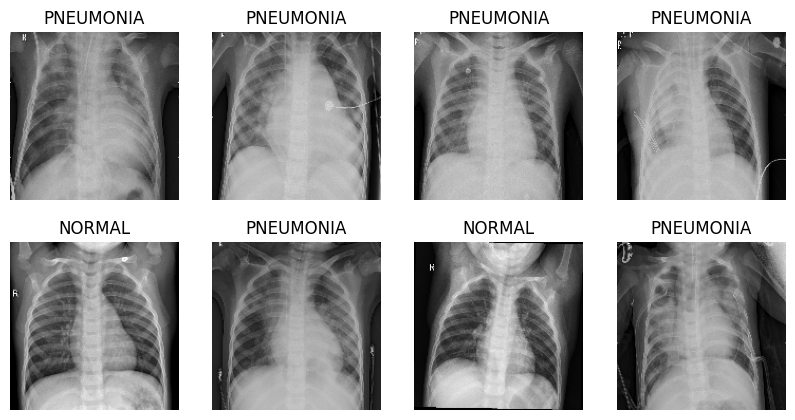

In [16]:
images, labels = next(iter(train_ds))
labels = labels.numpy().ravel().astype(int)

plt.figure(figsize=(10, 5))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.show()

## 4. Build the Model (Transfer Learning)
Instead of training a network from scratch, we reuse **MobileNetV2**, already trained on millions of everyday images, and only train a small new "head" for our 2 classes. That's why it's fast and works well even with little data.

In [17]:
base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                      include_top=False, weights="imagenet")
base.trainable = False   # freeze the pre-trained part

model = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.Rescaling(1./127.5, offset=-1),   # scale pixels to [-1, 1]
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")    # probability of Pneumonia
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

## 5. Train
Just 3 epochs is enough for a demo.

In [18]:
history = model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 44s 298ms/step - accuracy: 0.8433 - loss: 0.3427 - val_accuracy: 0.9147 - val_loss: 0.2071
Epoch 2/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 37s 285ms/step - accuracy: 0.9262 - loss: 0.1866 - val_accuracy: 0.9329 - val_loss: 0.1671
Epoch 3/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 35s 270ms/step - accuracy: 0.9408 - loss: 0.1522 - val_accuracy: 0.9444 - val_loss: 0.1464


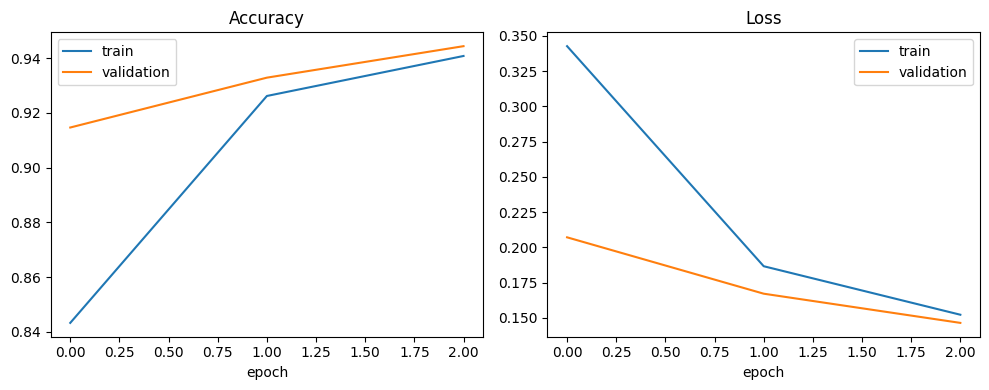

In [19]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout(); plt.show()

## 6. Evaluate on Unseen Test Images

20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 432ms/step
              precision    recall  f1-score   support

      NORMAL       0.93      0.55      0.69       234
   PNEUMONIA       0.78      0.97      0.87       390

    accuracy                           0.81       624
   macro avg       0.85      0.76      0.78       624
weighted avg       0.84      0.81      0.80       624



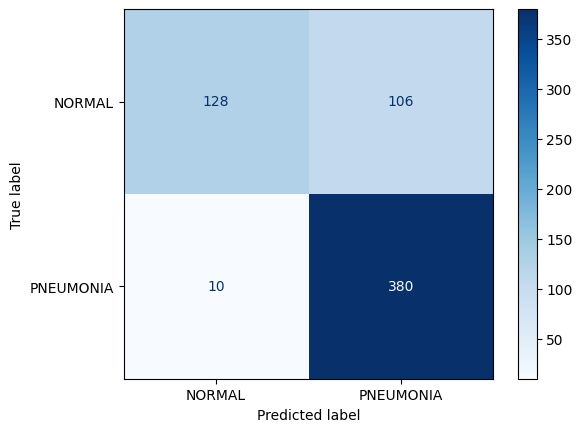

In [20]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int).ravel()
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(cmap="Blues")
plt.show()

Accuracy 81% hides the real story: Recall for Pneumonia = 97% (few missed cases), but Normal recall = 55% (many false alarms).

**How to read it (in healthcare):**
- **Recall (Pneumonia)** = of all real pneumonia cases, how many did we catch? A missed case (false negative) is the most dangerous mistake.
- **Precision (Pneumonia)** = when the model says pneumonia, how often is it right?
- Accuracy alone can be misleading when classes are imbalanced.

### Try it: predictions on a few test images

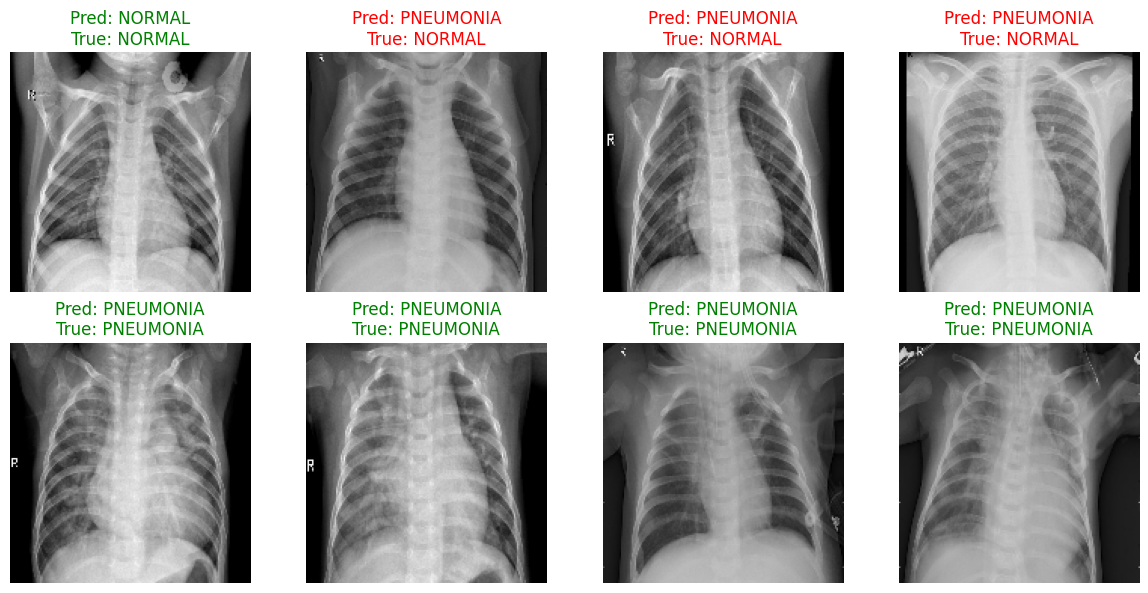

In [29]:
# Show 4 random Normal + 4 random Pneumonia test images
images_all = np.concatenate([x.numpy() for x, _ in test_ds])

rng = np.random.default_rng(1)
idx = np.concatenate([
    rng.choice(np.where(y_true == 0)[0], 4, replace=False),
    rng.choice(np.where(y_true == 1)[0], 4, replace=False),
])

plt.figure(figsize=(12, 6))
for k, i in enumerate(idx):
    plt.subplot(2, 4, k + 1)
    plt.imshow(images_all[i].astype("uint8"))
    pred, true = class_names[y_pred[i]], class_names[y_true[i]]
    plt.title(f"Pred: {pred}\nTrue: {true}", color="green" if pred == true else "red")
    plt.axis("off")
plt.tight_layout(); plt.show()

## Take-aways
1. Computer vision in healthcare = learning patterns from medical images to **support** clinicians.
2. **Transfer learning** lets us get good results quickly with limited data.
3. Always look beyond accuracy: **recall, precision, confusion matrix**.
4. Real-world use needs more: external validation, bias checks, explainability (e.g. Grad-CAM), and clinician oversight.